# Лабораторная работа №6

## Случайный лес

Регрессия общего рейтинга `Overall`. Случайный лес усредняет прогнозы деревьев: каждое дерево учится на своей бутстреп-выборке и случайном подмножестве признаков.

Данные — `fifa.csv`, тот же набор, что в лабораторных по разведочному анализу и градиентному спуску. Целевая переменная — `Overall`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_absolute_percentage_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

plt.rcParams['figure.dpi'] = 110

## Обзор данных

Смотрим размер таблицы, типы, пропуски и связь числовых признаков с `Overall`.

In [2]:
raw = pd.read_csv('fifa.csv')
print(raw.shape)
raw.info()

(18207, 18)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 18 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18207 non-null  int64  
 1   Name                      18207 non-null  object 
 2   Age                       18207 non-null  int64  
 3   Nationality               18207 non-null  object 
 4   Overall                   18207 non-null  int64  
 5   Potential                 18207 non-null  int64  
 6   Club                      17966 non-null  object 
 7   Value                     17955 non-null  float64
 8   Wage                      18207 non-null  float64
 9   Preferred Foot            18207 non-null  object 
 10  International Reputation  18159 non-null  float64
 11  Skill Moves               18159 non-null  float64
 12  Position                  18207 non-null  object 
 13  Joined                    18207 non-null  int64  

In [3]:
na = raw.isna().sum()
na = na[na > 0].to_frame('Пропуски')
na['Доля, %'] = (na['Пропуски'] / len(raw) * 100).round(2)
na

,Пропуски,"Доля, %"
Club,241,1.32
Value,252,1.38
International Reputation,48,0.26
Skill Moves,48,0.26
Contract Valid Until,289,1.59


In [4]:
num_preview = [
    'Age', 'Potential', 'Value', 'Wage', 'International Reputation',
    'Skill Moves', 'Joined', 'Height', 'Weight', 'Release Clause',
]
corr = raw[num_preview + ['Overall']].corr(numeric_only=True)['Overall']
corr.sort_values(ascending=False).round(3)

Overall                     1.000
Potential                   0.661
Value                       0.632
Release Clause              0.598
Wage                        0.572
International Reputation    0.499
Age                         0.452
Skill Moves                 0.414
Weight                      0.155
Height                      0.039
Joined                     -0.169
Name: Overall, dtype: float64

## Очистка

Пропуски чисел и категорий закрывает `SimpleImputer` внутри пайплайна: медианы и моды считаются только на обучающей части, в том числе на каждом фолде кросс-валидации.

До пайплайна остаются преобразования, которым не нужна статистика выборки:

- из `Contract Valid Until` достаётся год, пустые строки остаются пропусками;
- пропуск `Club` становится признаком свободного агента;
- 27 позиций сворачиваются в группы GK / DEF / MID / FWD, как в лабораторной по градиентному спуску.

`ID` и `Name` — идентификаторы. `Nationality` (164 значения) и `Club` (651 значение) в модель не входят: one-hot раздул бы матрицу. `Value` не заполняется медианой внутри групп `Overall`, потому что `Overall` — цель.

In [5]:
df = raw.copy()

df['Contract Year'] = pd.to_numeric(
    df['Contract Valid Until'].astype(str).str.extract(r'(\d{4})')[0],
    errors='coerce',
)
df['Is_Free_Agent'] = df['Club'].isna().astype(int)

pos_map = {
    'GK': 'GK',
    'CB': 'DEF', 'LCB': 'DEF', 'RCB': 'DEF', 'LB': 'DEF', 'RB': 'DEF', 'LWB': 'DEF', 'RWB': 'DEF',
    'CM': 'MID', 'LCM': 'MID', 'RCM': 'MID', 'CDM': 'MID', 'LDM': 'MID', 'RDM': 'MID',
    'CAM': 'MID', 'LAM': 'MID', 'RAM': 'MID', 'LM': 'MID', 'RM': 'MID',
    'ST': 'FWD', 'LS': 'FWD', 'RS': 'FWD', 'CF': 'FWD', 'LF': 'FWD', 'RF': 'FWD',
    'LW': 'FWD', 'RW': 'FWD',
}
df['Position_Group'] = df['Position'].map(pos_map).fillna('Other')

df = df.drop(columns=['ID', 'Name', 'Nationality', 'Club', 'Position', 'Contract Valid Until'])

print('Пропусков после подготовки:', int(df.isna().sum().sum()))
df.isna().sum()[lambda s: s > 0]

Пропусков после подготовки: 637


Value                       252
International Reputation     48
Skill Moves                  48
Contract Year               289
dtype: int64

## Разбиение

Цель — `Overall`. Обучающая и тестовая части делятся 80/20, `random_state=42`, как в предыдущих работах.

In [6]:
X = df.drop(columns=['Overall'])
y = df['Overall']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('train:', X_train.shape, 'test:', X_test.shape)
print('Overall train: среднее', round(y_train.mean(), 2), 'std', round(y_train.std(), 2))
print('Overall test:  среднее', round(y_test.mean(), 2), 'std', round(y_test.std(), 2))

train: (14565, 14) test: (3642, 14)
Overall train: среднее 66.23 std 6.93
Overall test:  среднее 66.29 std 6.82


## Пайплайн

`ColumnTransformer` готовит три группы признаков, затем их забирает `RandomForestRegressor`.

- `Value`, `Wage`, `Release Clause`: медиана, `log1p` (распределения с тяжёлым правым хвостом), `StandardScaler`.
- Остальные числа: медиана и `StandardScaler`.
- `Preferred Foot` и `Position_Group`: мода и one-hot с `drop='first'`. Бинарные столбцы не стандартизируются.

Деревьям масштаб признаков не нужен. Стандартизатор стоит в пайплайне по условию работы: он обучается на train и применяется к test вместе с моделью.

In [7]:
money_cols = ['Value', 'Wage', 'Release Clause']
num_cols = [
    'Age', 'Potential', 'International Reputation', 'Skill Moves',
    'Joined', 'Contract Year', 'Height', 'Weight', 'Is_Free_Agent',
]
cat_cols = ['Preferred Foot', 'Position_Group']


def make_pipeline():
    money_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
        ('scaler', StandardScaler()),
    ])
    num_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ])
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False)),
    ])
    preprocess = ColumnTransformer([
        ('money', money_pipe, money_cols),
        ('num', num_pipe, num_cols),
        ('cat', cat_pipe, cat_cols),
    ])
    return Pipeline([
        ('prep', preprocess),
        ('rf', RandomForestRegressor(random_state=42, n_jobs=-1)),
    ])


baseline = make_pipeline()
baseline

,steps,"[('prep', ...), ('rf', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('money', ...), ('num', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


## Базовая модель

Лес с параметрами по умолчанию: 100 деревьев, глубина не ограничена, лист может состоять из одного объекта.

In [8]:
baseline.fit(X_train, y_train)

pred_train = baseline.predict(X_train)
pred_test = baseline.predict(X_test)

## Метрики

MSE и RMSE — в единицах рейтинга (RMSE ближе к шкале `Overall`). MAE — средняя абсолютная ошибка. R² — доля дисперсии, которую объясняет модель. MAPE — средняя абсолютная ошибка в процентах от истинного `Overall`; нулей в рейтинге нет, поэтому деление определено.

Метрики на train показывают, насколько лес запомнил обучающую выборку.

In [9]:
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mse = mean_squared_error(y_true, y_pred)
    return pd.Series({
        'MSE': mse,
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': float(np.sqrt(mse)),
        'R2': r2_score(y_true, y_pred),
        'MAPE, %': mean_absolute_percentage_error(y_true, y_pred) * 100,
    })


baseline_train = regression_metrics(y_train, pred_train)
baseline_test = regression_metrics(y_test, pred_test)
pd.DataFrame({'train': baseline_train, 'test': baseline_test}).round(4)

,train,test
MSE,0.0311,0.2288
MAE,0.0908,0.2403
RMSE,0.1762,0.4784
R2,0.9994,0.9951
"MAPE, %",0.1436,0.3795


## Прогноз и остатки

Точки на диагонали — точные прогнозы. Остаток равен `факт − прогноз`: разброс вокруг нуля показывает, где модель систематически завышает или занижает рейтинг.

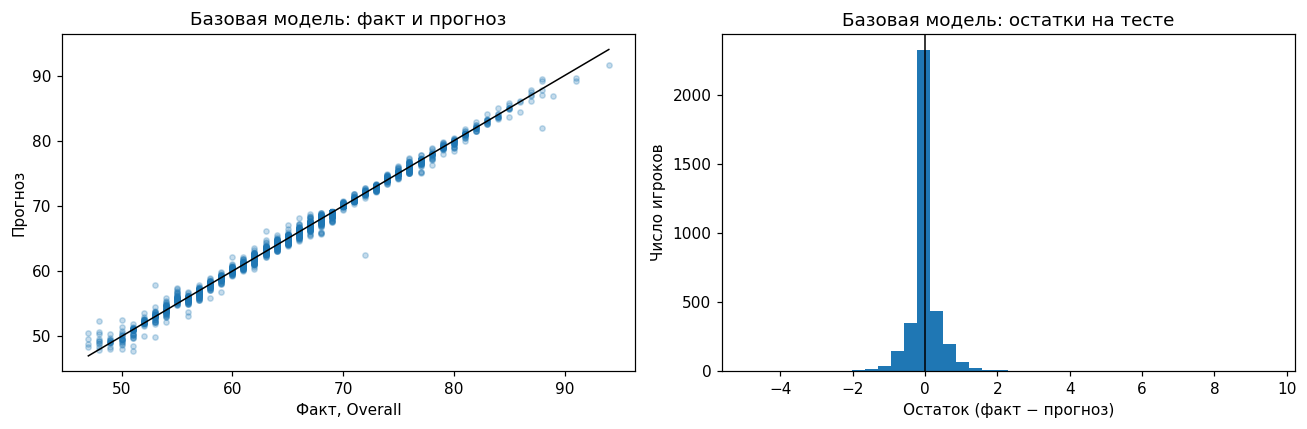

In [10]:
residuals = y_test.to_numpy() - pred_test

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, pred_test, alpha=0.25, s=12)
lims = [float(y_test.min()), float(y_test.max())]
axes[0].plot(lims, lims, color='black', linewidth=1)
axes[0].set_xlabel('Факт, Overall')
axes[0].set_ylabel('Прогноз')
axes[0].set_title('Базовая модель: факт и прогноз')

axes[1].hist(residuals, bins=40)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_xlabel('Остаток (факт − прогноз)')
axes[1].set_ylabel('Число игроков')
axes[1].set_title('Базовая модель: остатки на тесте')

plt.tight_layout()
plt.show()

## Подбор гиперпараметров

`GridSearchCV` перебирает число деревьев, глубину и минимальный размер листа. Сетка небольшая: на 18 тысячах строк полный перебор глубоких лесов занимает много времени. Критерий — RMSE на трёх фолдах (`neg_root_mean_squared_error`, у скорера знак обратный). Лучший пайплайн заново обучается на всей обучающей выборке.

In [11]:
param_grid = {
    'rf__n_estimators': [100, 200],
    'rf__max_depth': [None, 12, 20],
    'rf__min_samples_leaf': [1, 4],
}

search = GridSearchCV(
    make_pipeline(),
    param_grid,
    cv=3,
    scoring='neg_root_mean_squared_error',
    n_jobs=1,
    refit=True,
)
search.fit(X_train, y_train)

print('Лучшие параметры:', search.best_params_)
print('RMSE на кросс-валидации:', round(-search.best_score_, 4))

Лучшие параметры: {'rf__max_depth': 20, 'rf__min_samples_leaf': 1, 'rf__n_estimators': 200}
RMSE на кросс-валидации: 0.507


## Оценка с новыми параметрами

Те же пять метрик на train и test. Сравнение с базовым лесом — по тестовой выборке.

In [12]:
best = search.best_estimator_
tuned_train = regression_metrics(y_train, best.predict(X_train))
tuned_test = regression_metrics(y_test, best.predict(X_test))

pd.DataFrame({
    'baseline train': baseline_train,
    'baseline test': baseline_test,
    'tuned train': tuned_train,
    'tuned test': tuned_test,
}).round(4)

,baseline train,baseline test,tuned train,tuned test
MSE,0.0311,0.2288,0.0306,0.2243
MAE,0.0908,0.2403,0.0906,0.2390
RMSE,0.1762,0.4784,0.1749,0.4736
R2,0.9994,0.9951,0.9994,0.9952
"MAPE, %",0.1436,0.3795,0.1434,0.3778


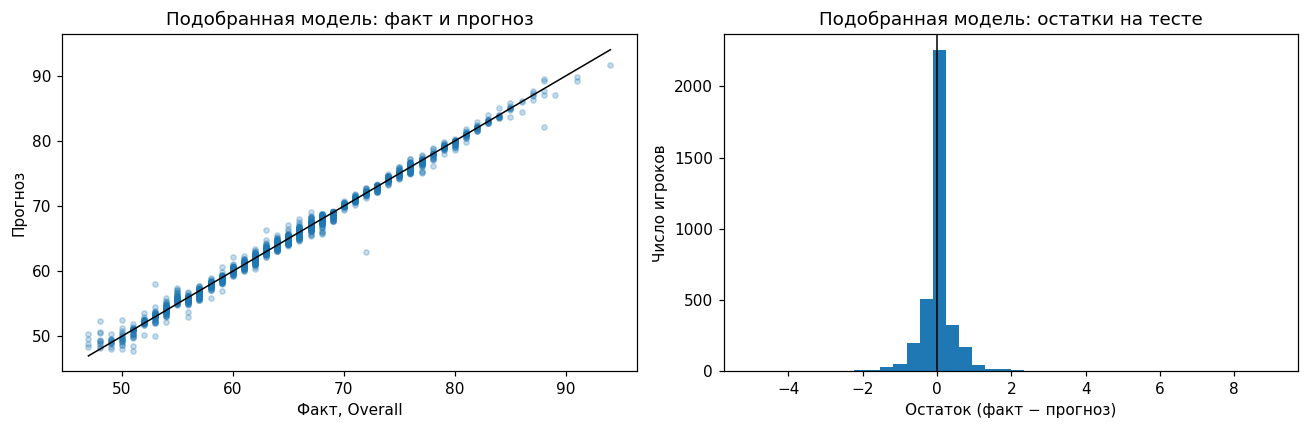

In [13]:
pred_test_tuned = best.predict(X_test)
residuals_tuned = y_test.to_numpy() - pred_test_tuned

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_test, pred_test_tuned, alpha=0.25, s=12)
lims = [float(y_test.min()), float(y_test.max())]
axes[0].plot(lims, lims, color='black', linewidth=1)
axes[0].set_xlabel('Факт, Overall')
axes[0].set_ylabel('Прогноз')
axes[0].set_title('Подобранная модель: факт и прогноз')

axes[1].hist(residuals_tuned, bins=40)
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_xlabel('Остаток (факт − прогноз)')
axes[1].set_ylabel('Число игроков')
axes[1].set_title('Подобранная модель: остатки на тесте')

plt.tight_layout()
plt.show()

## Важность признаков

Важность — средняя доля уменьшения критерия, которую признак даёт по всем деревьям леса. Имена берутся из подготовленной матрицы пайплайна: префиксы `money`, `num` и `cat` отброшены.

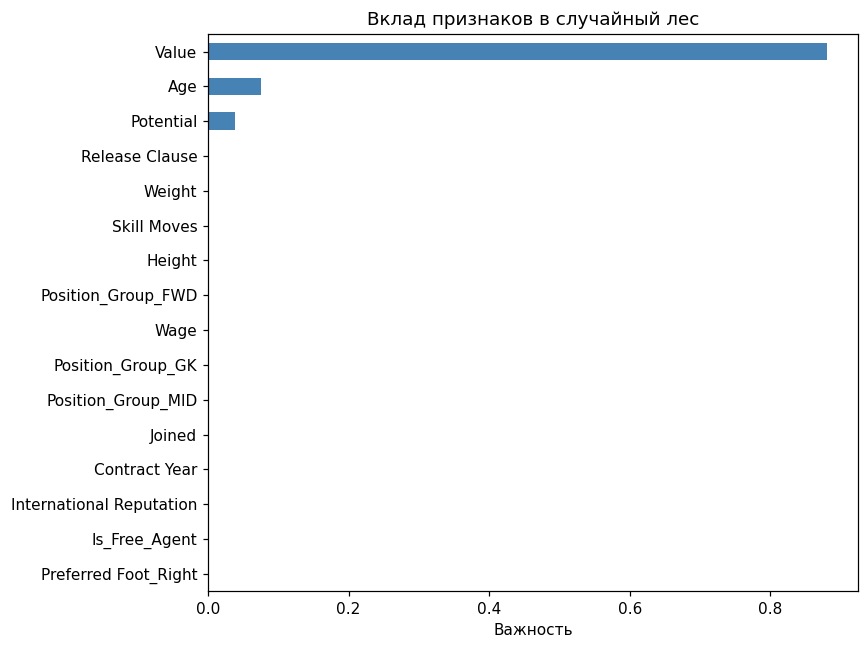

Наибольший вклад:
Value             0.8807
Age               0.0756
Potential         0.0376
Release Clause    0.0009
Weight            0.0008
Доля топ-3: 0.9939


In [14]:
feature_names = best.named_steps['prep'].get_feature_names_out()
importance = pd.Series(
    best.named_steps['rf'].feature_importances_,
    index=[name.split('__', 1)[-1] for name in feature_names],
)
importance = importance.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
importance.plot.barh(ax=ax, color='steelblue')
ax.set_xlabel('Важность')
ax.set_title('Вклад признаков в случайный лес')
plt.tight_layout()
plt.show()

ranked = importance.sort_values(ascending=False)
print('Наибольший вклад:')
print(ranked.head(5).round(4).to_string())
print('Доля топ-3:', round(float(ranked.head(3).sum()), 4))

## Вывод

Пайплайн заполняет пропуски и стандартизирует числа на обучающей выборке, затем строит регрессионный лес. На тесте базовая модель даёт RMSE 0.48 пункта рейтинга, MAE 0.24, R² 0.995 и MAPE 0.38%. Сетка выбрала 200 деревьев, глубину 20 и лист из одного объекта. Тестовый RMSE снизился до 0.47: у леса с параметрами по умолчанию запас уже был небольшой. На train RMSE около 0.17 — глубокие деревья запоминают выборку плотнее, чем обобщают её.

Почти весь вклад приходится на `Value` (0.88). В FIFA стоимость считается из рейтинга, поэтому признак почти повторяет цель. Дальше идут `Age` (0.08) и `Potential` (0.04). Вместе эти три признака дают 0.99 важности. Позиция и рабочая нога на графике почти не видны: при известной стоимости они мало что добавляют к `Overall`.